In [1]:
print("Network Traffic Analyzer")
print("Project initialized successfully!")

Network Traffic Analyzer
Project initialized successfully!


In [3]:
import pandas as pd

traffic_data = {
    "source_ip": [
        "192.168.1.10",
        "192.168.1.12",
        "192.168.1.10",
        "192.168.1.15",
        "192.168.1.12",
        "192.168.1.10",
        "192.168.1.20",
        "192.168.1.15"
    ],
    "destination_port": [
        80, 443, 80, 22, 443, 8080, 80, 22
    ],
    "packets": [
        120, 95, 140, 15, 110, 500, 85, 20
    ],
    "bytes_transferred": [
        12000, 8500, 15000, 2000,
        9200, 95000, 7800, 2500
    ]
}

df = pd.DataFrame(traffic_data)

print("Network Traffic Dataset")
display(df)

Network Traffic Dataset


,source_ip,destination_port,packets,bytes_transferred
0,192.168.1.10,80,120,12000
1,192.168.1.12,443,95,8500
2,192.168.1.10,80,140,15000
3,192.168.1.15,22,15,2000
4,192.168.1.12,443,110,9200
5,192.168.1.10,8080,500,95000
6,192.168.1.20,80,85,7800
7,192.168.1.15,22,20,2500


In [4]:
# Basic network traffic analysis

print("Total network records:", len(df))

print("Total packets:", df["packets"].sum())

print("Total bytes transferred:", df["bytes_transferred"].sum())

print("\\nTraffic by source IP:")

ip_summary = df.groupby("source_ip").agg(
    total_packets=("packets", "sum"),
    total_bytes=("bytes_transferred", "sum"),
    connection_count=("source_ip", "count")
)

display(ip_summary.sort_values("total_bytes", ascending=False))

Total network records: 8
Total packets: 1085
Total bytes transferred: 152000
\nTraffic by source IP:


,total_packets,total_bytes,connection_count
source_ip,,,
192.168.1.10,760,122000,3
192.168.1.12,205,17700,2
192.168.1.20,85,7800,1
192.168.1.15,35,4500,2


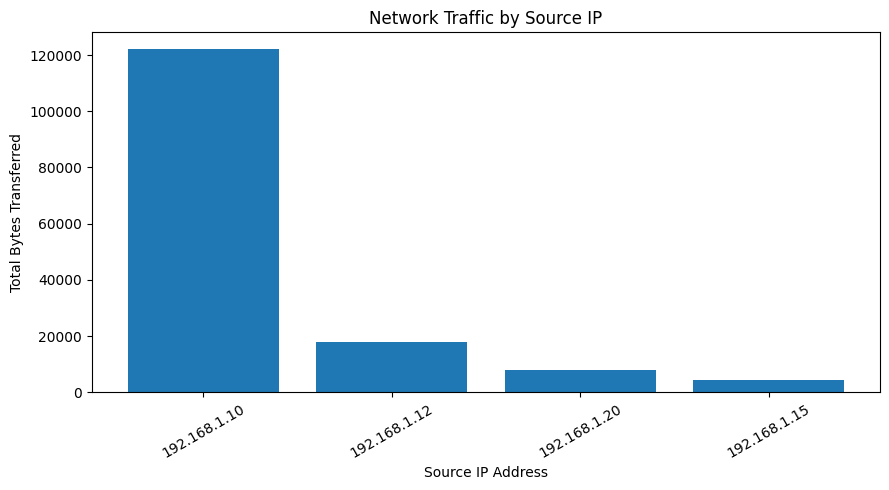

In [5]:
import matplotlib.pyplot as plt

ip_summary = ip_summary.sort_values(
    "total_bytes", ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    ip_summary.index,
    ip_summary["total_bytes"]
)

plt.title("Network Traffic by Source IP")
plt.xlabel("Source IP Address")
plt.ylabel("Total Bytes Transferred")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [6]:
# Define simple training thresholds
packet_threshold = 200
bytes_threshold = 30000

# Flag records that exceed either threshold
df["needs_review"] = (
    (df["packets"] > packet_threshold) |
    (df["bytes_transferred"] > bytes_threshold)
)

print("Traffic records flagged for review:")
display(df[df["needs_review"] == True])

print("Total records:", len(df))
print("Records flagged for review:", df["needs_review"].sum())

Traffic records flagged for review:


,source_ip,destination_port,packets,bytes_transferred,needs_review
5,192.168.1.10,8080,500,95000,True


Total records: 8
Records flagged for review: 1


Network Traffic Analysis Summary
--------------------------------
Total records: 8
Records flagged for review: 1
Other records: 7


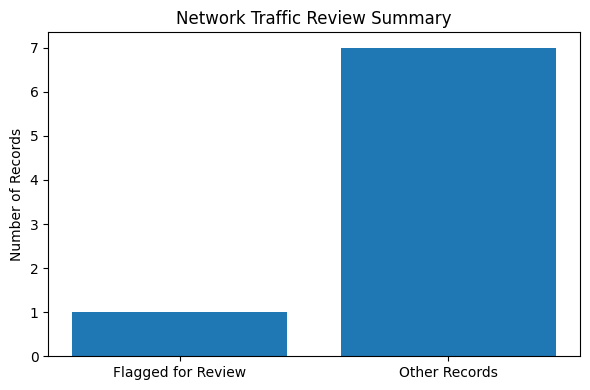

In [7]:
import matplotlib.pyplot as plt

flagged_count = int(df["needs_review"].sum())
normal_count = len(df) - flagged_count

print("Network Traffic Analysis Summary")
print("--------------------------------")
print("Total records:", len(df))
print("Records flagged for review:", flagged_count)
print("Other records:", normal_count)

plt.figure(figsize=(6, 4))
plt.bar(
    ["Flagged for Review", "Other Records"],
    [flagged_count, normal_count]
)

plt.title("Network Traffic Review Summary")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()